# License Plate Pipeline, CNN Character Classifier

Companion to notebook 95. Same problem (read characters off a license plate), different approach: instead of handing the plate crop to pytesseract, I segment it into individual characters and run a small CNN classifier on each character.

Why bother trying both? Because the OCR version (95) is easier to throw together but fails in weird ways, and the CNN version is more controllable. I can see the per-character confidence and decide what to reject.

Data: real Russian plate crops from the AUTO.RIA / Nomeroff Net plate OCR dataset (CC BY 4.0), loaded from `AY000554/Car_plate_OCR_dataset` on Hugging Face. Each image is a cropped plate and its file name is the plate text. I use the 2,845-image test archive (72MB) and split it 80/20 by plate into my own train and test sets. Russian plates use 12 letters that look like Latin ones (A B E K M H O P C T Y X) plus digits, so there are 22 character classes.

There are no per-character boxes in the data, so I build character training data with a simple trick: segment each plate with contours, and if the number of segments equals the length of the plate text, label the segments left to right. Plates where the counts don't match are skipped for training.

In [1]:
# !pip install opencv-python-headless torch -q
import warnings
warnings.filterwarnings("ignore")

import io, os, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
torch.manual_seed(0)
np.random.seed(0)

CHAR_W, CHAR_H = 32, 48
CLASSES = list("ABEKMHOPCTYX") + list("0123456789")  # 22 classes on Russian plates
print(f"{len(CLASSES)} classes")

22 classes


## Load real plates and cut them into characters

2845 real plate crops, e.g. ['A001BP54', 'A001PC71', 'A002KX152']


train plates usable: 1303/2276 -> 10939 characters
test plates usable:  319/569 -> 2668 characters


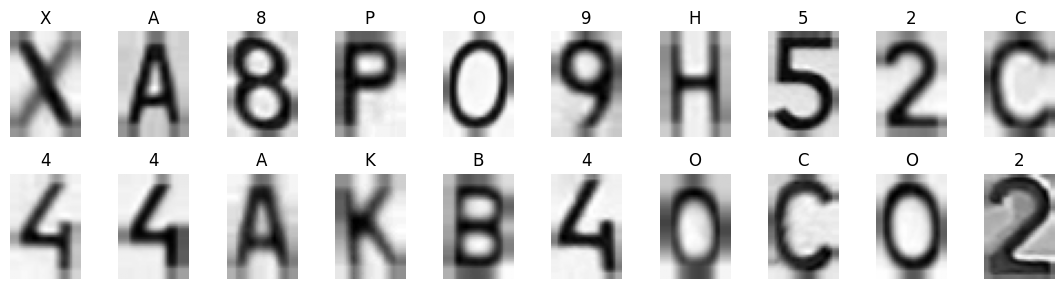

In [2]:
DATA = Path("../../data/plates_ru")
IMG_DIR = DATA / "test" / "img"
if not IMG_DIR.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    url = "https://huggingface.co/datasets/AY000554/Car_plate_OCR_dataset/resolve/main/test.zip"
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(DATA)

files = sorted(IMG_DIR.glob("*.png"))
texts = [f.stem for f in files]
print(f"{len(files)} real plate crops, e.g. {texts[:3]}")

def segment(gray):
    """Upscale, Otsu-threshold, keep character-shaped contours, sort left to right."""
    H, W = gray.shape
    g = cv2.resize(gray, (W * 2, H * 2)); H, W = g.shape
    _, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    cs, _ = cv2.findContours(bw, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    boxes = [cv2.boundingRect(c) for c in cs]
    boxes = [b for b in boxes if 0.25 * H < b[3] < 0.9 * H and 2 < b[2] < 0.2 * W and b[3] > b[2]]
    # drop boxes that sit inside another box (holes in 0, 8, B and so on)
    boxes = [b for b in boxes if not any(o != b and o[0] <= b[0] and o[1] <= b[1] and
                                         o[0] + o[2] >= b[0] + b[2] and o[1] + o[3] >= b[1] + b[3] for o in boxes)]
    crops = []
    for (x, y, w, h) in sorted(boxes):
        crop = cv2.copyMakeBorder(g[y:y + h, x:x + w], 4, 4, 4, 4, cv2.BORDER_REPLICATE)
        crops.append(cv2.resize(crop, (CHAR_W, CHAR_H)).astype(np.float32) / 255.0)
    return crops

rng = np.random.default_rng(0)
order = rng.permutation(len(files))
cut = int(0.8 * len(files))
train_plates, test_plates = order[:cut], order[cut:]

segs = {i: segment(cv2.imread(str(files[i]), cv2.IMREAD_GRAYSCALE)) for i in range(len(files))}
def char_set(plate_ids):
    X, y, used = [], [], 0
    for i in plate_ids:
        if len(segs[i]) == len(texts[i]) and all(ch in CLASSES for ch in texts[i]):
            X += segs[i]; y += [CLASSES.index(ch) for ch in texts[i]]; used += 1
    return np.stack(X)[..., None], np.array(y), used

X_tr, y_tr, used_tr = char_set(train_plates)
X_te, y_te, used_te = char_set(test_plates)
print(f"train plates usable: {used_tr}/{len(train_plates)} -> {len(X_tr)} characters")
print(f"test plates usable:  {used_te}/{len(test_plates)} -> {len(X_te)} characters")

fig, axes = plt.subplots(2, 10, figsize=(11, 3))
for ax, k in zip(axes.flat, rng.choice(len(X_tr), 20, replace=False)):
    ax.imshow(X_tr[k, ..., 0], cmap="gray"); ax.set_title(CLASSES[y_tr[k]]); ax.axis("off")
plt.tight_layout(); plt.show()

## Train the CNN

In [3]:
class CharCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3)
        self.c2 = nn.Conv2d(16, 32, 3)
        self.drop = nn.Dropout(0.3)
        self.fc1 = nn.Linear(32 * 10 * 6, 64)   # 48x32 input -> 10x6 after two conv+pool steps
        self.fc2 = nn.Linear(64, n_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = self.drop(x.flatten(1))
        return self.fc2(F.relu(self.fc1(x)))

def to_t(X):  # (N, H, W, 1) numpy -> (N, 1, H, W) tensor
    return torch.tensor(X).permute(0, 3, 1, 2)

cnn = CharCNN(len(CLASSES))
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
Xt, yt = to_t(X_tr), torch.tensor(y_tr)
for ep in range(6):
    cnn.train(); perm = torch.randperm(len(Xt)); losses = []
    for i in range(0, len(perm), 64):
        idx = perm[i:i + 64]
        opt.zero_grad()
        loss = F.cross_entropy(cnn(Xt[idx]), yt[idx])
        loss.backward(); opt.step(); losses.append(loss.item())
    print(f"epoch {ep}  mean_loss={np.mean(losses):.4f}")

def predict(X):
    cnn.eval()
    with torch.no_grad():
        return cnn(to_t(X)).argmax(1).numpy()

char_acc = (predict(X_te) == y_te).mean()
print(f"test character accuracy (characters from held-out plates): {char_acc:.3f}")

epoch 0  mean_loss=1.0740


epoch 1  mean_loss=0.2346


epoch 2  mean_loss=0.1944


epoch 3  mean_loss=0.1775


epoch 4  mean_loss=0.1667


epoch 5  mean_loss=0.1495


test character accuracy (characters from held-out plates): 0.981


## Read whole held-out plates

Now the full pipeline on the 569 held-out plates: segment, classify each piece, join. A plate only counts as correct if every character matches. Plates where segmentation finds the wrong number of pieces count as failures, because in real use I wouldn't know the true length.

segmentation found the right number of characters: 319/569 (56.1%)
plates read exactly right: 295/569 (51.8%)
exactly right when segmentation count was right: 295/319 (92.5%)


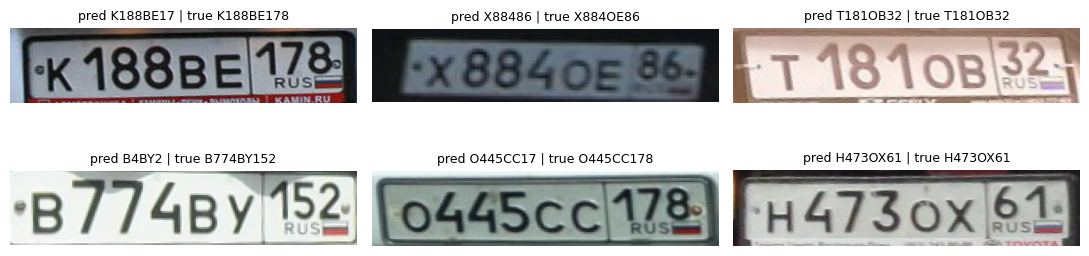

In [4]:
exact, seg_ok, exact_given_seg = 0, 0, 0
examples = []
for i in test_plates:
    crops = segs[i]
    pred = "".join(CLASSES[k] for k in predict(np.stack(crops)[..., None])) if crops else ""
    good_seg = len(crops) == len(texts[i])
    seg_ok += good_seg
    exact += pred == texts[i]
    exact_given_seg += good_seg and pred == texts[i]
    if len(examples) < 6:
        examples.append((i, pred))
n = len(test_plates)
print(f"segmentation found the right number of characters: {seg_ok}/{n} ({seg_ok / n:.1%})")
print(f"plates read exactly right: {exact}/{n} ({exact / n:.1%})")
print(f"exactly right when segmentation count was right: {exact_given_seg}/{seg_ok} ({exact_given_seg / seg_ok:.1%})")

fig, axes = plt.subplots(2, 3, figsize=(11, 3.5))
for ax, (i, pred) in zip(axes.flat, examples):
    ax.imshow(cv2.cvtColor(cv2.imread(str(files[i])), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"pred {pred} | true {texts[i]}", fontsize=9)
plt.tight_layout(); plt.show()

## Reflection vs the OCR version (notebook 95)

Results on real plates: the CNN classifies 98.1% of individual characters correctly on held-out plates, and when segmentation finds the right number of pieces, it reads 92.5% of plates exactly. But segmentation only gets the count right on 56.1% of held-out plates, so end to end the pipeline reads 51.8% of plates (295 of 569) exactly right. Segmentation is clearly the bottleneck, not the classifier.

Two caveats on those numbers. The character labels come from my count-matching trick, so a plate where segmentation splits one character and merges two others would still get used with wrong labels; I haven't measured how often that happens. And the character accuracy is measured only on plates that segmented cleanly, which are the easier ones.

Two ways to read characters off a plate:

- **OCR (notebook 95):** one function call, but the failure mode is opaque. Tesseract returns a string and you either trust it or you don't. Hard to debug per character.
- **CNN here:** more code, more places to break, but I can look at the per-character softmax and *see* which one the model wasn't sure about, and I can tell segmentation failures apart from classification failures, like above.

If I came back to this I'd:
1. Use a real detection model (YOLOv8 nano) for the plate-region step, feeding crops like these.
2. Replace segmentation + per-character CNN with a CRNN trained end to end with CTC loss on the full 45K-plate dataset. That removes the segmentation bottleneck entirely, and it's what most real plate readers do.